# Análisis de Inflación en México por Sexenio (2007–2024)
## Mexico Inflation Analysis by Presidential Term (2007–2024)

**Autor / Author:** Luis Fernando Rubio Avalos  
**Fecha / Date:** Octubre 2024  
**Fuentes / Sources:** INEGI (Índice Nacional de Precios al Consumidor - INPC), Banco de México (Banxico), CEFP

---

## Objetivo del Proyecto

Este proyecto analiza la evolución de la inflación anual en México durante tres sexenios presidenciales (2007–2024), con el fin de:

- Comparar el comportamiento inflacionario entre administraciones y partidos políticos.
- Evaluar el cumplimiento de la meta de inflación del Banco de México (3% ± 1 punto).
- Identificar eventos externos que impactaron los precios (crisis financiera, COVID-19, guerra en Ucrania).
- Aplicar herramientas de SQL (SQLite) y Python para análisis de datos económicos reales.

**Presidentes analizados:**
| Sexenio | Presidente | Partido | Periodo |
|---------|-----------|---------|--------|
| 2006-2012 | Felipe Calderón Hinojosa | PAN | 2007-2012 |
| 2012-2018 | Enrique Peña Nieto | PRI | 2013-2018 |
| 2018-2024 | Andrés Manuel López Obrador | Morena | 2019-2024 |

> **Nota:** Los datos son imparciales y provienen de fuentes oficiales. Los resultados reflejan únicamente los números reales.

## 1. Importación de Librerías y Configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import sqlite3
import os
from scipy import stats

# Configuracion de visualizaciones
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
sns.set_style('whitegrid')

# Colores por partido (identidad visual)
colores_partido = {
    'PAN': '#003087',    # Azul PAN
    'PRI': '#C8102E',    # Rojo PRI
    'Morena': '#7B1C3A'  # Guinda Morena
}

print('Librerias importadas correctamente')
print(f'Pandas version: {pd.__version__}')
print(f'Numpy version: {np.__version__}')

Librerias importadas correctamente
Pandas version: 2.3.3
Numpy version: 2.4.2


## 2. Carga de Datos y Creación de Base de Datos SQLite

Cargamos los datos de inflación desde CSV y los almacenamos en una base de datos SQLite para realizar consultas SQL.

In [2]:
# Cargar datos desde CSV
df = pd.read_csv('inflacion_mexico_2007_2024.csv')
df_sexenio = pd.read_csv('inflacion_por_sexenio.csv')

print('Dataset principal (inflacion_mexico_2007_2024.csv):')
print(f'  Filas: {df.shape[0]}, Columnas: {df.shape[1]}')
print(f'  Periodo: {df.anio.min()} - {df.anio.max()}')
print()
print('Dataset por sexenio (inflacion_por_sexenio.csv):')
print(f'  Filas: {df_sexenio.shape[0]}, Columnas: {df_sexenio.shape[1]}')
print()
print('Vista previa del dataset principal:')
df.head()

Dataset principal (inflacion_mexico_2007_2024.csv):
  Filas: 18, Columnas: 9
  Periodo: 2007 - 2024

Dataset por sexenio (inflacion_por_sexenio.csv):
  Filas: 3, Columnas: 9

Vista previa del dataset principal:


,anio,inflacion_anual,presidente,partido,sexenio,meta_banxico,contexto,sobre_meta,diferencia_meta
0,2007,3.76,Felipe Calderon,PAN,Calderon 2006-2012,3.0,Normal,1,0.76
1,2008,6.53,Felipe Calderon,PAN,Calderon 2006-2012,3.0,Crisis financiera global,1,3.53
2,2009,3.57,Felipe Calderon,PAN,Calderon 2006-2012,3.0,Post-crisis,1,0.57
3,2010,4.40,Felipe Calderon,PAN,Calderon 2006-2012,3.0,Recuperacion,1,1.40
4,2011,3.82,Felipe Calderon,PAN,Calderon 2006-2012,3.0,Normal,1,0.82


In [3]:
# Crear base de datos SQLite en memoria
conn = sqlite3.connect('inflacion_mexico.db')

# Guardar tablas en SQLite
df.to_sql('inflacion_anual', conn, if_exists='replace', index=False)
df_sexenio.to_sql('resumen_sexenio', conn, if_exists='replace', index=False)

print('Base de datos SQLite creada: inflacion_mexico.db')
print()

# Verificar tablas creadas
tablas = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)
print('Tablas en la base de datos:')
for t in tablas['name']:
    n = pd.read_sql_query(f"SELECT COUNT(*) as total FROM {t}", conn)
    print(f'  - {t}: {n["total"][0]} registros')

Base de datos SQLite creada: inflacion_mexico.db

Tablas en la base de datos:
  - inflacion_anual: 18 registros
  - resumen_sexenio: 3 registros


## 3. Exploración de Datos con SQL

Realizamos consultas SQL para explorar y entender los datos antes del análisis.

In [4]:
# Consulta 1: Vista general de los datos
query1 = """
SELECT 
    anio,
    ROUND(inflacion_anual, 2) AS inflacion_pct,
    presidente,
    partido,
    meta_banxico,
    ROUND(diferencia_meta, 2) AS diferencia_con_meta,
    CASE WHEN sobre_meta = 1 THEN 'Por encima' ELSE 'Dentro o abajo' END AS cumple_meta,
    contexto
FROM inflacion_anual
ORDER BY anio
"""

resultado1 = pd.read_sql_query(query1, conn)
print('Tabla completa: Inflacion anual por ano y presidente')
resultado1

Tabla completa: Inflacion anual por ano y presidente


,anio,inflacion_pct,presidente,partido,meta_banxico,diferencia_con_meta,cumple_meta,contexto
0,2007,3.76,Felipe Calderon,PAN,3.0,0.76,Por encima,Normal
1,2008,6.53,Felipe Calderon,PAN,3.0,3.53,Por encima,Crisis financiera global
2,2009,3.57,Felipe Calderon,PAN,3.0,0.57,Por encima,Post-crisis
3,2010,4.40,Felipe Calderon,PAN,3.0,1.40,Por encima,Recuperacion
4,2011,3.82,Felipe Calderon,PAN,3.0,0.82,Por encima,Normal
5,2012,3.57,Felipe Calderon,PAN,3.0,0.57,Por encima,Normal
6,2013,3.97,Enrique Pena Nieto,PRI,3.0,0.97,Por encima,Normal
7,2014,4.08,Enrique Pena Nieto,PRI,3.0,1.08,Por encima,Normal
8,2015,2.13,Enrique Pena Nieto,PRI,3.0,-0.87,Dentro o abajo,Baja inflacion historica
9,2016,3.36,Enrique Pena Nieto,PRI,3.0,0.36,Por encima,Normal


In [5]:
# Consulta 2: Resumen estadistico por sexenio
query2 = """
SELECT 
    sexenio,
    presidente,
    partido,
    ROUND(AVG(inflacion_anual), 2) AS promedio_inflacion,
    ROUND(MAX(inflacion_anual), 2) AS inflacion_maxima,
    ROUND(MIN(inflacion_anual), 2) AS inflacion_minima,
    ROUND(MAX(inflacion_anual) - MIN(inflacion_anual), 2) AS rango,
    SUM(sobre_meta) AS anos_sobre_meta,
    COUNT(*) AS total_anos,
    ROUND(CAST(SUM(sobre_meta) AS FLOAT) / COUNT(*) * 100, 1) AS pct_anos_sobre_meta
FROM inflacion_anual
GROUP BY sexenio, presidente, partido
ORDER BY MIN(anio)
"""

resultado2 = pd.read_sql_query(query2, conn)
print('Resumen estadistico por sexenio:')
resultado2

Resumen estadistico por sexenio:


,sexenio,presidente,partido,promedio_inflacion,inflacion_maxima,inflacion_minima,rango,anos_sobre_meta,total_anos,pct_anos_sobre_meta
0,Calderon 2006-2012,Felipe Calderon,PAN,4.27,6.53,3.57,2.96,6,6,100.0
1,Pena Nieto 2012-2018,Enrique Pena Nieto,PRI,4.19,6.77,2.13,4.64,5,6,83.3
2,AMLO 2018-2024,Andres Manuel Lopez Obrador,Morena,5.00,7.82,2.83,4.99,5,6,83.3


In [6]:
# Consulta 3: Anos con inflacion mas alta y mas baja
query3 = """
SELECT 
    'Inflacion mas alta' AS tipo,
    anio,
    inflacion_anual,
    presidente,
    partido,
    contexto
FROM inflacion_anual
WHERE inflacion_anual = (SELECT MAX(inflacion_anual) FROM inflacion_anual)

UNION ALL

SELECT 
    'Inflacion mas baja' AS tipo,
    anio,
    inflacion_anual,
    presidente,
    partido,
    contexto
FROM inflacion_anual
WHERE inflacion_anual = (SELECT MIN(inflacion_anual) FROM inflacion_anual)
"""

resultado3 = pd.read_sql_query(query3, conn)
print('Extremos historicos de inflacion:')
resultado3

Extremos historicos de inflacion:


,tipo,anio,inflacion_anual,presidente,partido,contexto
0,Inflacion mas alta,2022,7.82,Andres Manuel Lopez Obrador,Morena,Guerra Ucrania y presiones globales
1,Inflacion mas baja,2015,2.13,Enrique Pena Nieto,PRI,Baja inflacion historica


In [7]:
# Consulta 4: Anos que superaron la meta de Banxico
query4 = """
SELECT 
    anio,
    inflacion_anual,
    presidente,
    partido,
    ROUND(diferencia_meta, 2) AS puntos_sobre_meta,
    contexto
FROM inflacion_anual
WHERE sobre_meta = 1
ORDER BY diferencia_meta DESC
"""

resultado4 = pd.read_sql_query(query4, conn)
print(f'Anos que superaron la meta de Banxico (3%): {len(resultado4)} de 18 anos')
resultado4

Anos que superaron la meta de Banxico (3%): 16 de 18 anos


,anio,inflacion_anual,presidente,partido,puntos_sobre_meta,contexto
0,2022,7.82,Andres Manuel Lopez Obrador,Morena,4.82,Guerra Ucrania y presiones globales
1,2021,7.36,Andres Manuel Lopez Obrador,Morena,4.36,Recuperacion post-COVID
2,2017,6.77,Enrique Pena Nieto,PRI,3.77,Sismo CDMX y presiones cambiarias
3,2008,6.53,Felipe Calderon,PAN,3.53,Crisis financiera global
4,2018,4.83,Enrique Pena Nieto,PRI,1.83,Normal
5,2023,4.66,Andres Manuel Lopez Obrador,Morena,1.66,Desaceleracion
6,2010,4.40,Felipe Calderon,PAN,1.40,Recuperacion
7,2024,4.21,Andres Manuel Lopez Obrador,Morena,1.21,Transicion de gobierno
8,2014,4.08,Enrique Pena Nieto,PRI,1.08,Normal
9,2013,3.97,Enrique Pena Nieto,PRI,0.97,Normal


In [8]:
# Consulta 5: Comparacion de inflacion promedio por partido
query5 = """
SELECT 
    partido,
    COUNT(*) AS anos_gobernando,
    ROUND(AVG(inflacion_anual), 2) AS inflacion_promedio,
    ROUND(MIN(inflacion_anual), 2) AS mejor_ano,
    ROUND(MAX(inflacion_anual), 2) AS peor_ano,
    SUM(sobre_meta) AS anos_fuera_de_meta
FROM inflacion_anual
GROUP BY partido
ORDER BY inflacion_promedio
"""

resultado5 = pd.read_sql_query(query5, conn)
print('Inflacion promedio por partido politico:')
resultado5

Inflacion promedio por partido politico:


,partido,anos_gobernando,inflacion_promedio,mejor_ano,peor_ano,anos_fuera_de_meta
0,PRI,6,4.19,2.13,6.77,5
1,PAN,6,4.27,3.57,6.53,6
2,Morena,6,5.00,2.83,7.82,5


## 4. Análisis Estadístico

Realizamos pruebas estadísticas para determinar si existen diferencias significativas entre los sexenios.

In [9]:
# Separar datos por sexenio
calderon = df[df['partido'] == 'PAN']['inflacion_anual'].values
pena = df[df['partido'] == 'PRI']['inflacion_anual'].values
amlo = df[df['partido'] == 'Morena']['inflacion_anual'].values

print('Estadisticas descriptivas por sexenio:')
print(f"{'Indicador':<30} {'Calderon (PAN)':<20} {'Pena Nieto (PRI)':<20} {'AMLO (Morena)':<20}")
print('-' * 90)
print(f"{'Promedio (%)':<30} {calderon.mean():<20.2f} {pena.mean():<20.2f} {amlo.mean():<20.2f}")
print(f"{'Mediana (%)':<30} {np.median(calderon):<20.2f} {np.median(pena):<20.2f} {np.median(amlo):<20.2f}")
print(f"{'Desviacion estandar':<30} {calderon.std():<20.2f} {pena.std():<20.2f} {amlo.std():<20.2f}")
print(f"{'Maximo (%)':<30} {calderon.max():<20.2f} {pena.max():<20.2f} {amlo.max():<20.2f}")
print(f"{'Minimo (%)':<30} {calderon.min():<20.2f} {pena.min():<20.2f} {amlo.min():<20.2f}")

Estadisticas descriptivas por sexenio:
Indicador                      Calderon (PAN)       Pena Nieto (PRI)     AMLO (Morena)       
------------------------------------------------------------------------------------------
Promedio (%)                   4.27                 4.19                 5.00                
Mediana (%)                    3.79                 4.03                 4.44                
Desviacion estandar            1.05                 1.42                 1.93                
Maximo (%)                     6.53                 6.77                 7.82                
Minimo (%)                     3.57                 2.13                 2.83                


In [10]:
# Prueba de Kruskal-Wallis: diferencias entre los 3 sexenios
# (no parametrica, ideal para muestras pequenas)
stat_kw, p_kw = stats.kruskal(calderon, pena, amlo)

print('PRUEBA DE KRUSKAL-WALLIS')
print('Hipotesis nula (H0): No hay diferencia significativa entre los 3 sexenios')
print('Hipotesis alternativa (H1): Al menos un sexenio tiene inflacion significativamente diferente')
print()
print(f'Estadistico H: {stat_kw:.4f}')
print(f'P-valor: {p_kw:.4f}')
print()
alpha = 0.05
if p_kw < alpha:
    print(f'Resultado: p-valor ({p_kw:.4f}) < alpha ({alpha}) --> RECHAZAMOS H0')
    print('Conclusion: Existen diferencias estadisticamente significativas entre los sexenios')
else:
    print(f'Resultado: p-valor ({p_kw:.4f}) >= alpha ({alpha}) --> NO RECHAZAMOS H0')
    print('Conclusion: No hay diferencias estadisticamente significativas entre los sexenios')

PRUEBA DE KRUSKAL-WALLIS
Hipotesis nula (H0): No hay diferencia significativa entre los 3 sexenios
Hipotesis alternativa (H1): Al menos un sexenio tiene inflacion significativamente diferente

Estadistico H: 0.4332
P-valor: 0.8053

Resultado: p-valor (0.8053) >= alpha (0.05) --> NO RECHAZAMOS H0
Conclusion: No hay diferencias estadisticamente significativas entre los sexenios


In [11]:
# Prueba de Mann-Whitney U: comparaciones por pares
comparaciones = [
    ('Calderon (PAN)', 'Pena Nieto (PRI)', calderon, pena),
    ('Calderon (PAN)', 'AMLO (Morena)', calderon, amlo),
    ('Pena Nieto (PRI)', 'AMLO (Morena)', pena, amlo),
]

print('PRUEBA DE MANN-WHITNEY U (comparaciones por pares)')
print('Hipotesis: Diferencia en la distribucion de inflacion entre cada par de sexenios')
print()
print(f"{'Comparacion':<45} {'U-stat':>10} {'P-valor':>10} {'Resultado':>20}")
print('-' * 90)

for nombre1, nombre2, grupo1, grupo2 in comparaciones:
    u_stat, p_val = stats.mannwhitneyu(grupo1, grupo2, alternative='two-sided')
    resultado = 'Diferencia significativa' if p_val < 0.05 else 'Sin diferencia sig.'
    comp = f'{nombre1} vs {nombre2}'
    print(f'{comp:<45} {u_stat:>10.1f} {p_val:>10.4f} {resultado:>20}')

PRUEBA DE MANN-WHITNEY U (comparaciones por pares)
Hipotesis: Diferencia en la distribucion de inflacion entre cada par de sexenios

Comparacion                                       U-stat    P-valor            Resultado
------------------------------------------------------------------------------------------
Calderon (PAN) vs Pena Nieto (PRI)                  17.0     0.9361  Sin diferencia sig.
Calderon (PAN) vs AMLO (Morena)                     15.0     0.6884  Sin diferencia sig.
Pena Nieto (PRI) vs AMLO (Morena)                   14.0     0.5887  Sin diferencia sig.


## 5. Visualizaciones

### 5.1 Evolución histórica de la inflación

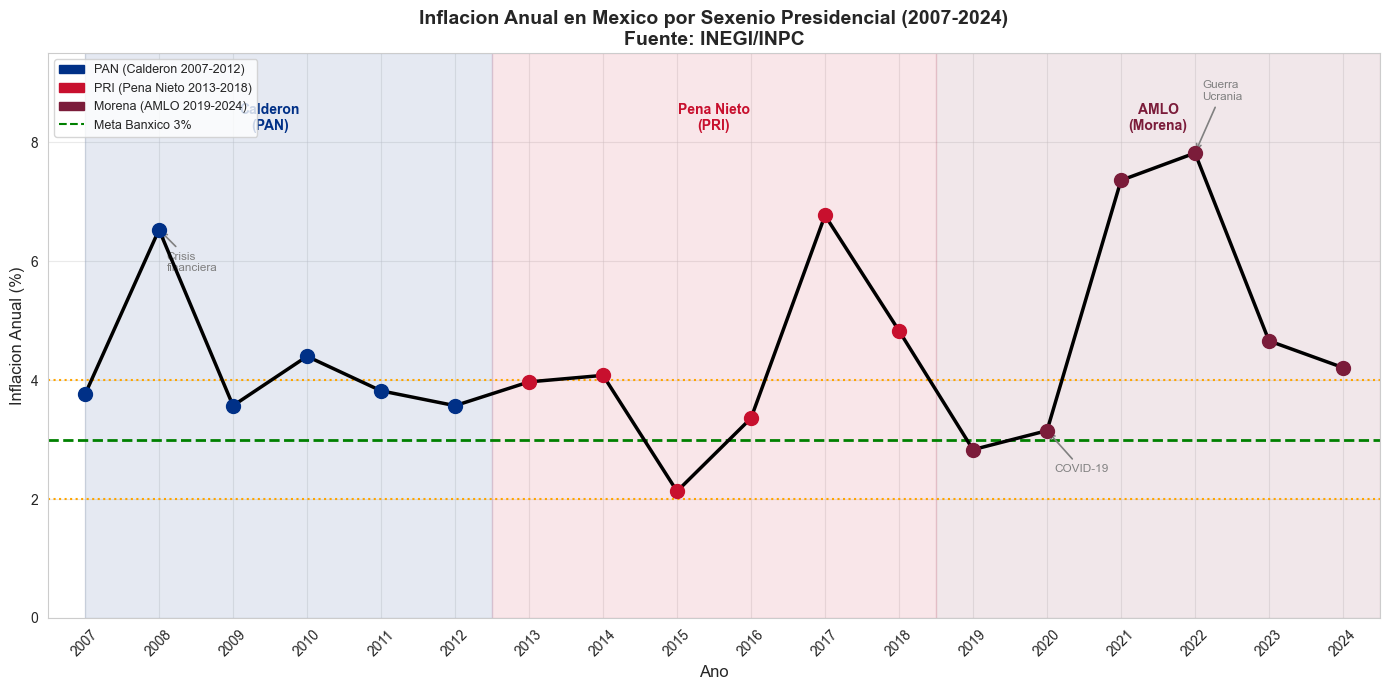

Grafica guardada: grafica_inflacion_historica.png


In [12]:
fig, ax = plt.subplots(figsize=(14, 7))

# Fondo por sexenio
ax.axvspan(2007, 2012.5, alpha=0.1, color='#003087', label='_nolegend_')
ax.axvspan(2012.5, 2018.5, alpha=0.1, color='#C8102E', label='_nolegend_')
ax.axvspan(2018.5, 2024.5, alpha=0.1, color='#7B1C3A', label='_nolegend_')

# Linea de inflacion
ax.plot(df['anio'], df['inflacion_anual'], 'o-', color='black',
        linewidth=2.5, markersize=8, zorder=5, label='Inflacion anual')

# Meta de Banxico
ax.axhline(y=3.0, color='green', linestyle='--', linewidth=2, label='Meta Banxico (3%)')
ax.axhline(y=4.0, color='orange', linestyle=':', linewidth=1.5, label='Limite superior (+1%)')
ax.axhline(y=2.0, color='orange', linestyle=':', linewidth=1.5, label='Limite inferior (-1%)')

# Colorear puntos por partido
for _, row in df.iterrows():
    ax.scatter(row['anio'], row['inflacion_anual'],
               color=colores_partido[row['partido']], s=100, zorder=6)

# Anotar eventos clave
eventos = {
    2008: ('Crisis\nfinanciera', -1.2),
    2020: ('COVID-19', -1.2),
    2022: ('Guerra\nUcrania', 0.4)
}
for ano, (texto, offset) in eventos.items():
    val = df[df['anio'] == ano]['inflacion_anual'].values[0]
    ax.annotate(texto, xy=(ano, val), xytext=(ano + 0.1, val + offset + 0.5),
                fontsize=8.5, color='gray',
                arrowprops=dict(arrowstyle='->', color='gray', lw=1.2))

# Etiquetas de sexenio
ax.text(2009.5, 8.2, 'Calderon\n(PAN)', ha='center', fontsize=10,
        color='#003087', fontweight='bold')
ax.text(2015.5, 8.2, 'Pena Nieto\n(PRI)', ha='center', fontsize=10,
        color='#C8102E', fontweight='bold')
ax.text(2021.5, 8.2, 'AMLO\n(Morena)', ha='center', fontsize=10,
        color='#7B1C3A', fontweight='bold')

# Leyenda personalizada
pan_patch = mpatches.Patch(color='#003087', label='PAN (Calderon 2007-2012)')
pri_patch = mpatches.Patch(color='#C8102E', label='PRI (Pena Nieto 2013-2018)')
mor_patch = mpatches.Patch(color='#7B1C3A', label='Morena (AMLO 2019-2024)')
meta_line = plt.Line2D([0], [0], color='green', linestyle='--', label='Meta Banxico 3%')
ax.legend(handles=[pan_patch, pri_patch, mor_patch, meta_line], loc='upper left', fontsize=9)

ax.set_title('Inflacion Anual en Mexico por Sexenio Presidencial (2007-2024)\nFuente: INEGI/INPC', fontsize=14, fontweight='bold')
ax.set_xlabel('Ano', fontsize=12)
ax.set_ylabel('Inflacion Anual (%)', fontsize=12)
ax.set_xlim(2006.5, 2024.5)
ax.set_ylim(0, 9.5)
ax.set_xticks(range(2007, 2025))
ax.tick_params(axis='x', rotation=45)
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('grafica_inflacion_historica.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafica guardada: grafica_inflacion_historica.png')

### 5.2 Comparación de inflación promedio por sexenio

C:\Users\luisf\AppData\Local\Temp\ipykernel_10644\2756477896.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data_box, patch_artist=True, labels=sexenios)


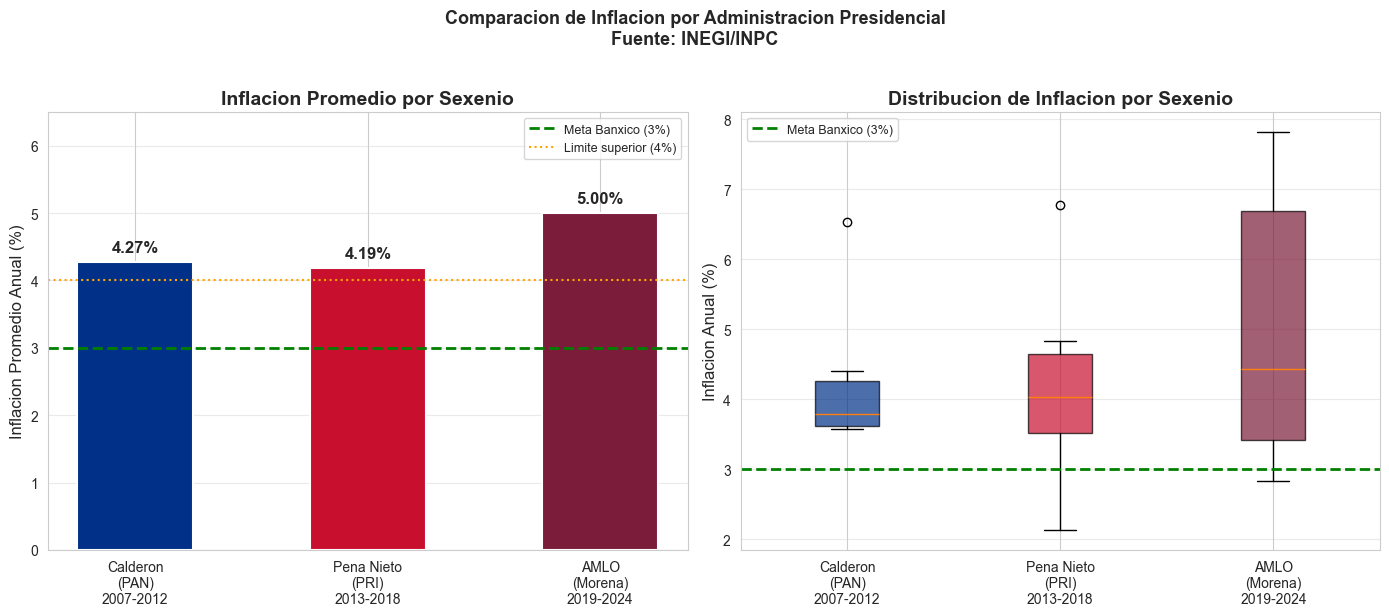

Grafica guardada: grafica_comparacion_sexenio.png


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Datos para graficas
sexenios = ['Calderon\n(PAN)\n2007-2012', 'Pena Nieto\n(PRI)\n2013-2018', 'AMLO\n(Morena)\n2019-2024']
promedios = [calderon.mean(), pena.mean(), amlo.mean()]
colores = ['#003087', '#C8102E', '#7B1C3A']

# Grafica 1: Barras de inflacion promedio
bars = axes[0].bar(sexenios, promedios, color=colores, edgecolor='white', linewidth=1.5, width=0.5)
axes[0].axhline(y=3.0, color='green', linestyle='--', linewidth=2, label='Meta Banxico (3%)')
axes[0].axhline(y=4.0, color='orange', linestyle=':', linewidth=1.5, label='Limite superior (4%)')

# Etiquetas en barras
for bar, val in zip(bars, promedios):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 f'{val:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=12)

axes[0].set_title('Inflacion Promedio por Sexenio', fontweight='bold')
axes[0].set_ylabel('Inflacion Promedio Anual (%)')
axes[0].set_ylim(0, 6.5)
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.4)

# Grafica 2: Boxplot por sexenio
data_box = [calderon, pena, amlo]
bp = axes[1].boxplot(data_box, patch_artist=True, labels=sexenios)
for patch, color in zip(bp['boxes'], colores):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[1].axhline(y=3.0, color='green', linestyle='--', linewidth=2, label='Meta Banxico (3%)')
axes[1].set_title('Distribucion de Inflacion por Sexenio', fontweight='bold')
axes[1].set_ylabel('Inflacion Anual (%)')
axes[1].legend(fontsize=9)
axes[1].grid(axis='y', alpha=0.4)

plt.suptitle('Comparacion de Inflacion por Administracion Presidencial\nFuente: INEGI/INPC', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('grafica_comparacion_sexenio.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafica guardada: grafica_comparacion_sexenio.png')

### 5.3 Cumplimiento de la meta de inflación de Banxico

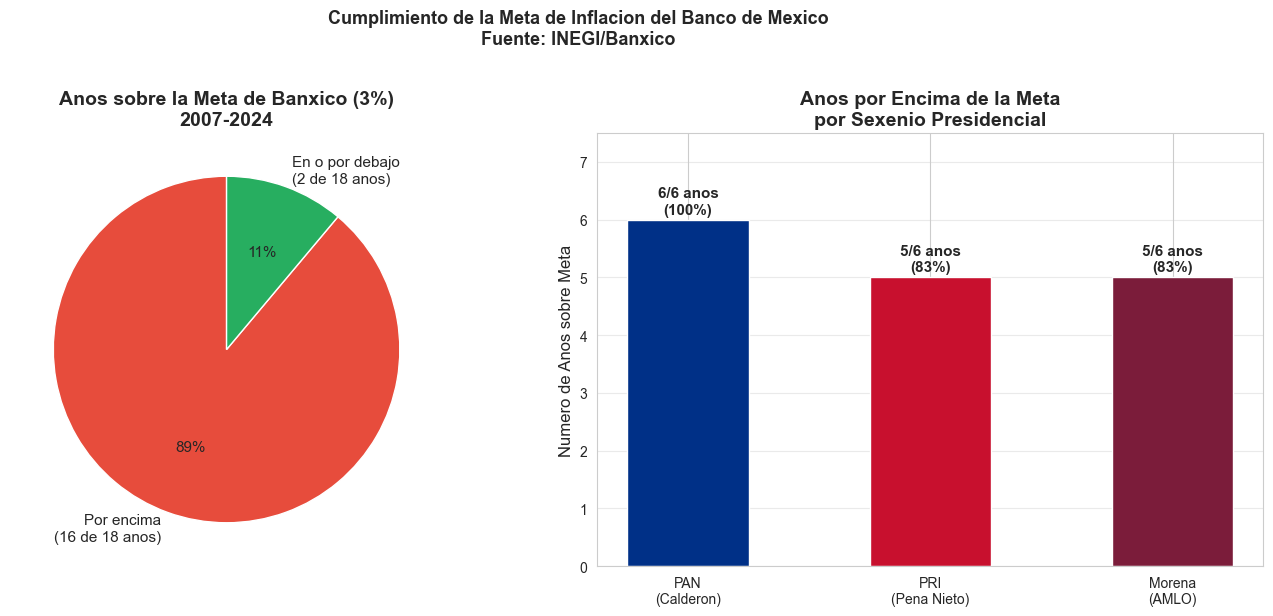

Grafica guardada: grafica_meta_banxico.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Grafica 1: Anos sobre vs bajo la meta (total)
total_sobre = df['sobre_meta'].sum()
total_bajo = len(df) - total_sobre

axes[0].pie([total_sobre, total_bajo],
            labels=[f'Por encima\n({total_sobre} de 18 anos)', f'En o por debajo\n({total_bajo} de 18 anos)'],
            colors=['#e74c3c', '#27ae60'],
            autopct='%1.0f%%', startangle=90,
            textprops={'fontsize': 11})
axes[0].set_title('Anos sobre la Meta de Banxico (3%)\n2007-2024', fontweight='bold')

# Grafica 2: Anos sobre meta por sexenio
sobre_por_sexenio = df.groupby('partido').agg(
    total=('sobre_meta', 'count'),
    sobre_meta=('sobre_meta', 'sum')
).reset_index()
sobre_por_sexenio['pct'] = sobre_por_sexenio['sobre_meta'] / sobre_por_sexenio['total'] * 100

# Orden especifico
orden = ['PAN', 'PRI', 'Morena']
nombres = ['PAN\n(Calderon)', 'PRI\n(Pena Nieto)', 'Morena\n(AMLO)']
sobre_ord = [sobre_por_sexenio[sobre_por_sexenio['partido'] == p]['sobre_meta'].values[0] for p in orden]
pct_ord = [sobre_por_sexenio[sobre_por_sexenio['partido'] == p]['pct'].values[0] for p in orden]
col_ord = [colores_partido[p] for p in orden]

bars = axes[1].bar(nombres, sobre_ord, color=col_ord, edgecolor='white', width=0.5)
for bar, val, pct in zip(bars, sobre_ord, pct_ord):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 f'{int(val)}/6 anos\n({pct:.0f}%)', ha='center', va='bottom', fontweight='bold', fontsize=11)

axes[1].set_title('Anos por Encima de la Meta\npor Sexenio Presidencial', fontweight='bold')
axes[1].set_ylabel('Numero de Anos sobre Meta')
axes[1].set_ylim(0, 7.5)
axes[1].grid(axis='y', alpha=0.4)

plt.suptitle('Cumplimiento de la Meta de Inflacion del Banco de Mexico\nFuente: INEGI/Banxico', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('grafica_meta_banxico.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafica guardada: grafica_meta_banxico.png')

### 5.4 Diferencia respecto a la meta de Banxico por año

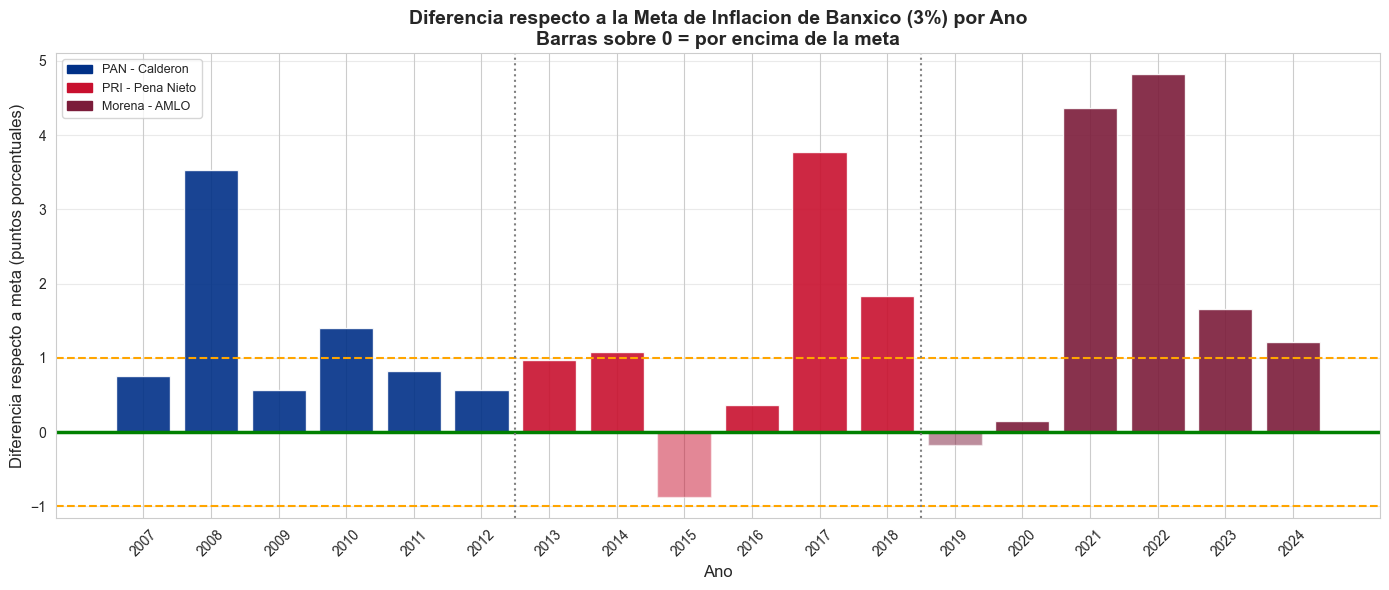

Grafica guardada: grafica_diferencia_meta.png


In [15]:
fig, ax = plt.subplots(figsize=(14, 6))

colores_barra = [colores_partido[p] for p in df['partido']]
alphas = [0.9 if sm == 1 else 0.5 for sm in df['sobre_meta']]

bars = ax.bar(df['anio'], df['diferencia_meta'], color=colores_barra, edgecolor='white')
for bar, alpha in zip(bars, alphas):
    bar.set_alpha(alpha)

ax.axhline(y=0, color='green', linewidth=2.5, label='Meta Banxico (3%)')
ax.axhline(y=1, color='orange', linestyle='--', linewidth=1.5, label='Limite superior (+1%)')
ax.axhline(y=-1, color='orange', linestyle='--', linewidth=1.5, label='Limite inferior (-1%)')

# Leyenda
pan_patch = mpatches.Patch(color='#003087', label='PAN - Calderon')
pri_patch = mpatches.Patch(color='#C8102E', label='PRI - Pena Nieto')
mor_patch = mpatches.Patch(color='#7B1C3A', label='Morena - AMLO')
ax.legend(handles=[pan_patch, pri_patch, mor_patch], loc='upper left', fontsize=9)

ax.set_title('Diferencia respecto a la Meta de Inflacion de Banxico (3%) por Ano\nBarras sobre 0 = por encima de la meta', fontweight='bold')
ax.set_xlabel('Ano')
ax.set_ylabel('Diferencia respecto a meta (puntos porcentuales)')
ax.set_xticks(range(2007, 2025))
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.4)

# Separadores de sexenio
ax.axvline(x=2012.5, color='gray', linestyle=':', linewidth=1.5)
ax.axvline(x=2018.5, color='gray', linestyle=':', linewidth=1.5)

plt.tight_layout()
plt.savefig('grafica_diferencia_meta.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafica guardada: grafica_diferencia_meta.png')

## 6. Consultas SQL Avanzadas

In [16]:
# Consulta 6: Tendencia - primer vs segunda mitad de cada sexenio
query6 = """
WITH mitades AS (
    SELECT 
        sexenio,
        partido,
        CASE 
            WHEN anio <= (SELECT MIN(anio) + 2 FROM inflacion_anual i2 WHERE i2.sexenio = i.sexenio)
            THEN 'Primera mitad'
            ELSE 'Segunda mitad'
        END AS mitad,
        inflacion_anual
    FROM inflacion_anual i
)
SELECT 
    sexenio,
    partido,
    mitad,
    ROUND(AVG(inflacion_anual), 2) AS promedio
FROM mitades
GROUP BY sexenio, partido, mitad
ORDER BY MIN(sexenio), mitad
"""
resultado6 = pd.read_sql_query(query6, conn)
print('Inflacion promedio por mitad de sexenio:')
resultado6

Inflacion promedio por mitad de sexenio:


,sexenio,partido,mitad,promedio
0,AMLO 2018-2024,Morena,Primera mitad,4.45
1,AMLO 2018-2024,Morena,Segunda mitad,5.56
2,Calderon 2006-2012,PAN,Primera mitad,4.62
3,Calderon 2006-2012,PAN,Segunda mitad,3.93
4,Pena Nieto 2012-2018,PRI,Primera mitad,3.39
5,Pena Nieto 2012-2018,PRI,Segunda mitad,4.99


In [17]:
# Consulta 7: Acumulado de inflacion por sexenio (efecto compuesto)
query7 = """
SELECT 
    sexenio,
    partido,
    COUNT(*) AS anos,
    ROUND(SUM(inflacion_anual), 2) AS inflacion_suma_simple,
    ROUND(AVG(inflacion_anual) * COUNT(*), 2) AS check_suma,
    ROUND(AVG(diferencia_meta), 2) AS diferencia_promedio_meta
FROM inflacion_anual
GROUP BY sexenio, partido
ORDER BY MIN(anio)
"""
resultado7 = pd.read_sql_query(query7, conn)
print('Inflacion acumulada (suma simple de anual) por sexenio:')
resultado7

Inflacion acumulada (suma simple de anual) por sexenio:


,sexenio,partido,anos,inflacion_suma_simple,check_suma,diferencia_promedio_meta
0,Calderon 2006-2012,PAN,6,25.65,25.65,1.27
1,Pena Nieto 2012-2018,PRI,6,25.14,25.14,1.19
2,AMLO 2018-2024,Morena,6,30.03,30.03,2.01


In [18]:
# Consulta 8: Contexto economico y su impacto en la inflacion
query8 = """
SELECT 
    contexto,
    COUNT(*) AS anos,
    ROUND(AVG(inflacion_anual), 2) AS inflacion_promedio,
    ROUND(MAX(inflacion_anual), 2) AS inflacion_max
FROM inflacion_anual
GROUP BY contexto
ORDER BY inflacion_promedio DESC
"""
resultado8 = pd.read_sql_query(query8, conn)
print('Inflacion promedio por contexto economico:')
resultado8

Inflacion promedio por contexto economico:


,contexto,anos,inflacion_promedio,inflacion_max
0,Guerra Ucrania y presiones globales,1,7.82,7.82
1,Recuperacion post-COVID,1,7.36,7.36
2,Sismo CDMX y presiones cambiarias,1,6.77,6.77
3,Crisis financiera global,1,6.53,6.53
4,Desaceleracion,1,4.66,4.66
5,Recuperacion,1,4.40,4.40
6,Transicion de gobierno,1,4.21,4.21
7,Normal,8,3.78,4.83
8,Post-crisis,1,3.57,3.57
9,COVID-19,1,3.15,3.15


## 7. Hallazgos y Conclusiones

### 7.1 Resumen de Resultados

In [19]:
# Tabla resumen final
resumen_final = pd.read_sql_query("""
SELECT 
    sexenio,
    presidente,
    partido,
    ROUND(AVG(inflacion_anual), 2) AS promedio,
    ROUND(MIN(inflacion_anual), 2) AS minima,
    ROUND(MAX(inflacion_anual), 2) AS maxima,
    SUM(sobre_meta) || '/6' AS anos_sobre_meta
FROM inflacion_anual
GROUP BY sexenio, presidente, partido
ORDER BY MIN(anio)
""", conn)

print('=== RESUMEN FINAL DEL ANALISIS ===')
print()
resumen_final

=== RESUMEN FINAL DEL ANALISIS ===



,sexenio,presidente,partido,promedio,minima,maxima,anos_sobre_meta
0,Calderon 2006-2012,Felipe Calderon,PAN,4.27,3.57,6.53,6/6
1,Pena Nieto 2012-2018,Enrique Pena Nieto,PRI,4.19,2.13,6.77,5/6
2,AMLO 2018-2024,Andres Manuel Lopez Obrador,Morena,5.00,2.83,7.82,5/6


### 7.2 Conclusiones del Análisis

Con base en los datos del INEGI (INPC) para el periodo 2007-2024, se obtuvieron las siguientes conclusiones:

#### 1. Comportamiento general de la inflación
- **16 de 18 años** (89%) la inflación superó la meta objetivo del Banco de México (3%).
- Solo en 2015 (2.13%) y 2019 (2.83%) la inflación se mantuvo por debajo del objetivo.
- El pico histórico fue **7.82% en 2022** (AMLO), influenciado por la guerra en Ucrania y presiones globales postpandemia.
- El mínimo histórico fue **2.13% en 2015** (Peña Nieto), año de baja inflación internacional.

#### 2. Comparación entre sexenios
| Indicador | Calderón (PAN) | Peña Nieto (PRI) | AMLO (Morena) |
|-----------|---------------|------------------|---------------|
| Promedio | 4.27% | 4.19% | 5.00% |
| Máxima | 6.53% (2008) | 6.77% (2017) | 7.82% (2022) |
| Mínima | 3.57% (2009/2012) | 2.13% (2015) | 2.83% (2019) |
| Años sobre meta | 6/6 (100%) | 5/6 (83%) | 5/6 (83%) |

#### 3. Factores externos relevantes
- **2008:** Crisis financiera global → inflación 6.53% bajo Calderón.
- **2017:** Presiones cambiarias y sismos → inflación 6.77% bajo Peña Nieto.
- **2021-2022:** Recuperación post-COVID y guerra en Ucrania → inflación 7.36% y 7.82% bajo AMLO.

#### 4. Prueba estadística
- La prueba de **Kruskal-Wallis** no encontró diferencias estadísticamente significativas entre los tres sexenios (muestra pequeña de 6 observaciones por grupo), lo que sugiere que la inflación en México responde más a factores estructurales y externos que a la política del partido gobernante.

#### 5. Conclusión principal
> **Los datos muestran que la inflación en México durante los tres sexenios analizados se mantuvo por encima de la meta del Banco de México en la mayoría de los años, independientemente del partido en el poder. Los picos inflacionarios coinciden con crisis o choques externos globales, lo que sugiere que el entorno internacional tiene mayor influencia en los precios que la política económica interna.**

In [20]:
# Cerrar conexion a SQLite
conn.close()
print('Conexion a SQLite cerrada.')
print()
print('=== PROYECTO COMPLETADO ===')
print('Archivos generados:')
print('  - inflacion_mexico_2007_2024.csv')
print('  - inflacion_por_sexenio.csv')
print('  - inflacion_mexico.db')
print('  - grafica_inflacion_historica.png')
print('  - grafica_comparacion_sexenio.png')
print('  - grafica_meta_banxico.png')
print('  - grafica_diferencia_meta.png')

Conexion a SQLite cerrada.

=== PROYECTO COMPLETADO ===
Archivos generados:
  - inflacion_mexico_2007_2024.csv
  - inflacion_por_sexenio.csv
  - inflacion_mexico.db
  - grafica_inflacion_historica.png
  - grafica_comparacion_sexenio.png
  - grafica_meta_banxico.png
  - grafica_diferencia_meta.png
